# Flight Price Insights
Exploratory analysis of the bundled flight-price sample. Run all cells in order from a fresh Python kernel.

The dataset is preserved unchanged. Counts represent dataset records, not passenger demand or the entire flight market. Currency and source provenance are not documented; prices are shown in dataset units. This notebook describes associations, not causal effects or predictions.


In [1]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

candidates = [Path.cwd() / 'Flight_Analysis' / 'flight_price.xlsx', Path.cwd() / 'flight_price.xlsx']
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Run from the repository root or Flight_Analysis directory.')
project_root = data_path.resolve().parent.parent
image_dir = project_root / 'docs' / 'images'
image_dir.mkdir(parents=True, exist_ok=True)
raw = pd.read_excel(data_path)
df = raw.copy()
sns.set_theme(style='whitegrid', palette='deep')
print(f'Original dataset: {len(raw):,} rows, {raw.shape[1]} columns')
display(raw.head())


Original dataset: 10,683 rows, 11 columns


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


## Validate and prepare data
Keep original columns intact. Parse journey dates explicitly as day/month/year and departure times as hours/minutes. Unknown stop counts remain missing; they are excluded only from the stop-specific summary.


In [2]:
required = {'Price', 'Airline', 'Date_of_Journey', 'Dep_Time', 'Total_Stops', 'Route'}
assert required.issubset(df.columns), f'Missing columns: {required - set(df.columns)}'
df['Price'] = pd.to_numeric(df['Price'], errors='raise')
assert df['Price'].notna().all() and np.isfinite(df['Price']).all() and df['Price'].ge(0).all()
df['Journey_Date'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y', errors='raise')
df['Month_Number'] = df['Journey_Date'].dt.month
df['Month_Name'] = df['Journey_Date'].dt.month_name()
df['Weekday_Number'] = df['Journey_Date'].dt.day_of_week
df['Weekday_Name'] = df['Journey_Date'].dt.day_name()
df['Departure_Hour'] = pd.to_datetime(df['Dep_Time'], format='%H:%M', errors='raise').dt.hour

def parse_stops(values):
    labels = values.astype('string').str.strip().str.lower()
    valid = labels.isna() | labels.eq('non-stop') | labels.str.fullmatch(r'\d+ stops?').fillna(False)
    if not valid.all():
        raise ValueError(f'Unrecognized stop labels: {labels[~valid].tolist()}')
    return pd.to_numeric(labels.replace('non-stop', '0').str.replace(r' stops?$', '', regex=True)).astype('Int64')

df['Stops'] = parse_stops(df['Total_Stops'])
# A route A -> B has one leg and zero intermediate stops.
route_legs = df['Route'].astype('string').str.count('→').astype('Int64')
route_stops = (route_legs - 1).where(route_legs.ge(1))
comparable = df['Stops'].notna() & route_stops.notna()
route_mismatches = int(df.loc[comparable, 'Stops'].ne(route_stops[comparable]).sum())
quality = pd.Series({
    'Records': len(df), 'Duplicate rows (retained)': int(raw.duplicated().sum()),
    'Missing routes': int(raw['Route'].isna().sum()),
    'Missing stop counts': int(df['Stops'].isna().sum()),
    'Routes unsuitable for stop cross-check': int(route_stops.isna().sum()),
    'Route / stop-count disagreements': route_mismatches,
})
display(quality.to_frame('Count'))
print(f"Journey dates: {df['Journey_Date'].min().date()} to {df['Journey_Date'].max().date()}")


,Count
Records,10683
Duplicate rows (retained),220
Missing routes,1
Missing stop counts,1
Routes unsuitable for stop cross-check,1
Route / stop-count disagreements,0


Journey dates: 2019-03-01 to 2019-06-27


## Price distribution and outliers
Retain all records, including duplicates and high prices, to describe the supplied sample. Without provenance, identical rows cannot safely be assumed to be collection errors. Boxplot outliers are not automatically invalid observations.


,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


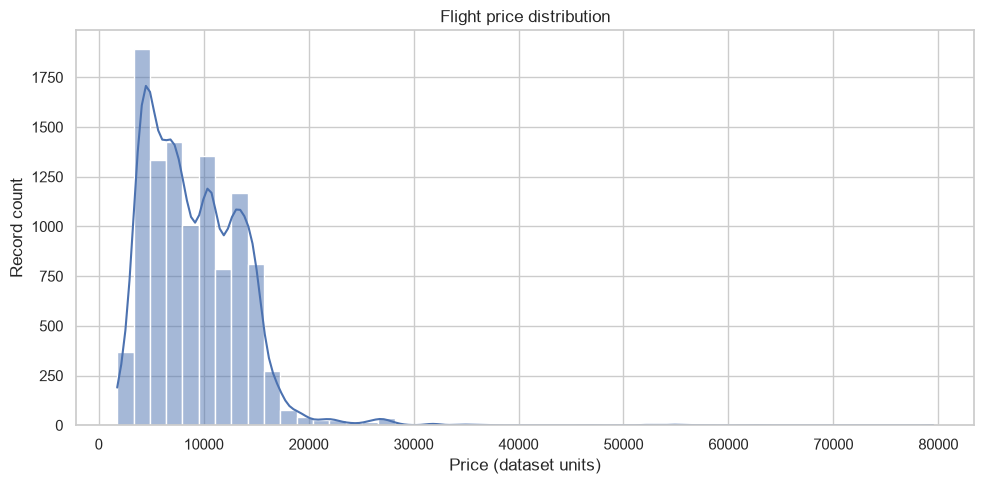

Prices outside the 1.5-IQR fences: 94; retained in analysis.


In [3]:
display(df['Price'].describe().to_frame('Price'))
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x='Price', bins=50, kde=True, ax=ax)
ax.set(title='Flight price distribution', xlabel='Price (dataset units)', ylabel='Record count')
fig.tight_layout()
fig.savefig(image_dir / 'price-distribution.png', dpi=150)
plt.show()
q1, q3 = df['Price'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df['Price'].lt(q1 - 1.5 * iqr) | df['Price'].gt(q3 + 1.5 * iqr)
print(f'Prices outside the 1.5-IQR fences: {int(outliers.sum()):,}; retained in analysis.')


## Airline comparison
Compare distributions and medians as well as means. Airline groups can differ in routes and service classes; this is not an isolated estimate of airline pricing effects.


,Count,Mean,Median
Airline,,,
Jet Airways Business,6,58358.67,54747.0
Jet Airways,3849,11643.92,11467.0
Multiple carriers Premium economy,13,11418.85,11269.0
Multiple carriers,1196,10902.68,10197.0
Air India,1752,9611.21,9443.0
Vistara Premium economy,3,8962.33,9125.0
Vistara,479,7796.35,7980.0
Air Asia,319,5590.26,5162.0
GoAir,194,5861.06,5135.0


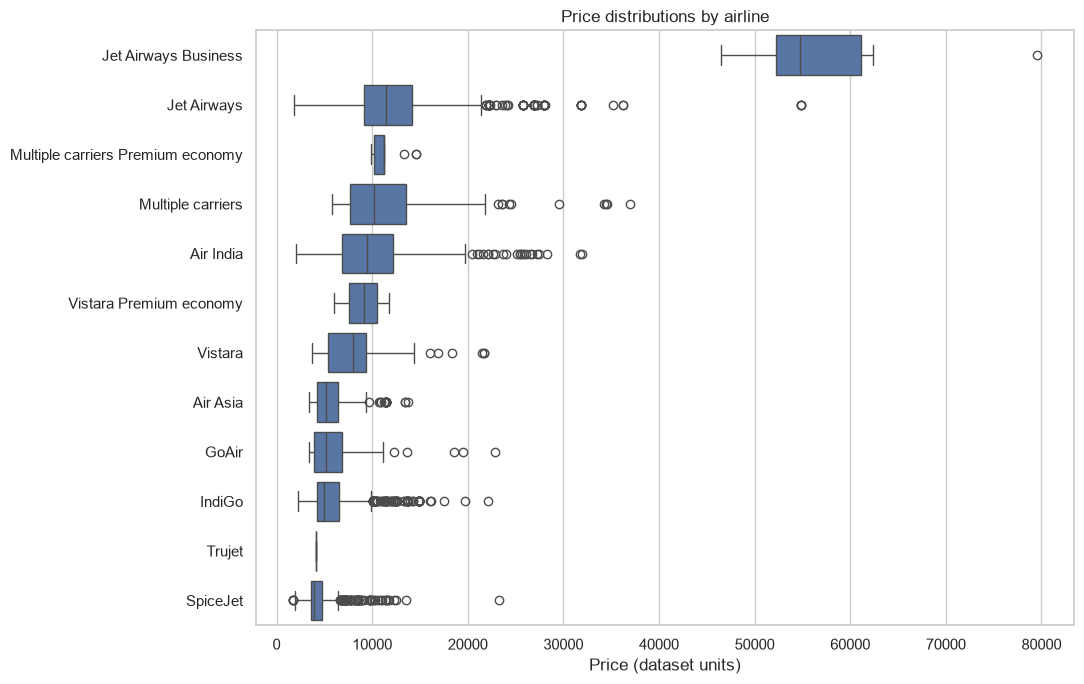

In [4]:
def summarize(column):
    return df.groupby(column, observed=True)['Price'].agg(Count='size', Mean='mean', Median='median').sort_index()

airline_summary = summarize('Airline').sort_values('Median', ascending=False)
display(airline_summary.round(2))
fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(data=df, x='Price', y='Airline', order=airline_summary.index, ax=ax)
ax.set(title='Price distributions by airline', xlabel='Price (dataset units)', ylabel='')
fig.tight_layout()
fig.savefig(image_dir / 'airline-prices.png', dpi=150)
plt.show()


## Journey month
Group by numeric months without overwriting them with text. This sample covers one year; pooling multiple years would require grouping by year and month instead. Record frequency is not proof of peak travel demand.


,Count,Mean,Median
Month,,,
March,2724,10673.21,9650.5
April,1079,5770.85,5073.0
May,3466,9127.25,8891.0
June,3414,8828.80,8610.0


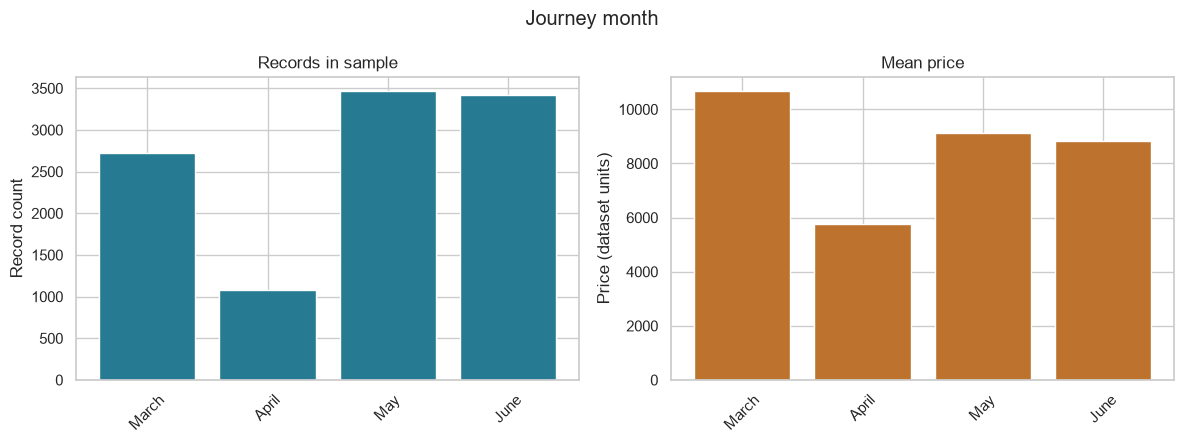

Largest sample group: May. Highest mean price: March.


In [5]:
assert df['Journey_Date'].dt.year.nunique() == 1, 'Use year-month groups for multi-year data.'
monthly = summarize('Month_Number')
monthly.index = pd.Index([calendar.month_name[int(m)] for m in monthly.index], name='Month')
display(monthly.round(2))

def plot_summary(table, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    labels = [str(v) for v in table.index]
    axes[0].bar(labels, table['Count'], color='#267b92')
    axes[0].set(title='Records in sample', ylabel='Record count')
    axes[1].bar(labels, table['Mean'], color='#bd732d')
    axes[1].set(title='Mean price', ylabel='Price (dataset units)')
    for ax in axes:
        ax.tick_params(axis='x', rotation=45)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(image_dir / filename, dpi=150)
    plt.show()

plot_summary(monthly, 'Journey month', 'monthly-prices.png')
print(f'Largest sample group: {monthly["Count"].idxmax()}. Highest mean price: {monthly["Mean"].idxmax()}.')


## Journey weekday
Dates are parsed consistently before weekdays are calculated. Means can reflect different route and airline mixes; they do not establish the cheapest day to book a ticket.


,Count,Mean,Median
Weekday,,,
Monday,1850,8499.53,7740.0
Tuesday,869,9026.15,8586.0
Wednesday,2079,9277.51,8529.0
Thursday,1832,8931.38,8367.0
Friday,909,9718.00,7229.0
Saturday,1670,8972.91,8372.0
Sunday,1474,9525.51,9454.0


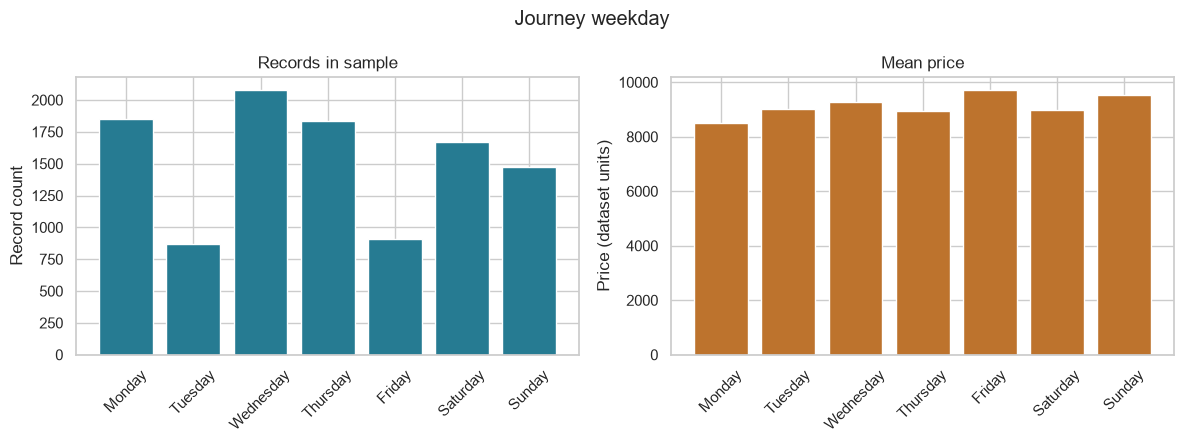

Highest mean: Friday; lowest mean: Monday.


In [6]:
weekday = summarize('Weekday_Number').reindex(range(7))
weekday.index = pd.Index(list(calendar.day_name), name='Weekday')
display(weekday.round(2))
plot_summary(weekday, 'Journey weekday', 'weekday-prices.png')
print(f'Highest mean: {weekday["Mean"].idxmax()}; lowest mean: {weekday["Mean"].idxmin()}.')


## Intermediate stops
Use the cleaned `Total_Stops` field: non-stop = 0, one stop = 1, and so on. The route string is a separate quality cross-check, not the source of an off-by-one count. Missing stop counts are excluded from this section only. Small groups need particular caution.


,Count,Mean,Median
Stops,,,
0,3491,5024.90,4667.0
1,5625,10594.12,10262.0
2,1520,12715.81,12760.0
3,45,13112.00,12954.0
4,1,17686.00,17686.0


Excluded from stop summary: 1 record(s).


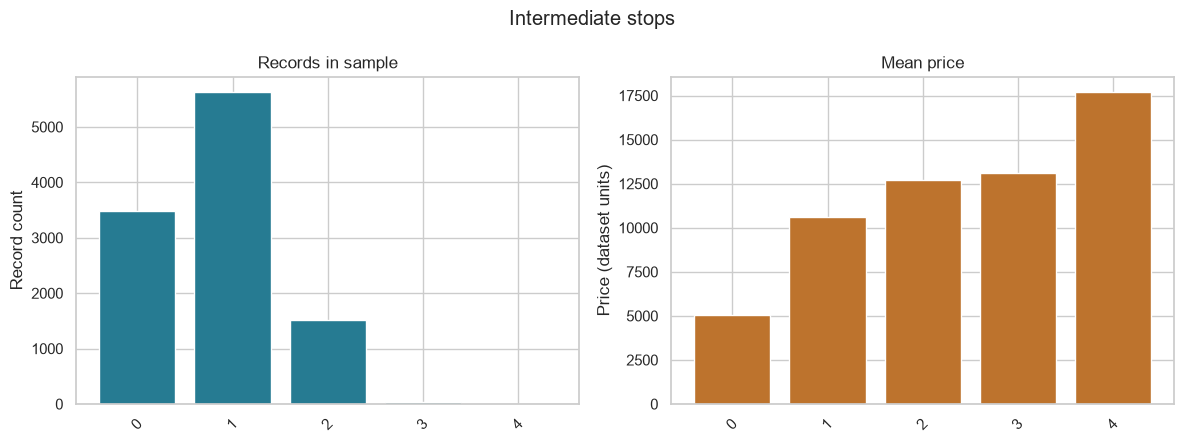

Groups with fewer than 30 records:


,Count,Mean,Median
Stops,,,
4,1,17686.0,17686.0


In [7]:
stops = summarize('Stops')
display(stops.round(2))
print(f'Excluded from stop summary: {df["Stops"].isna().sum()} record(s).')
plot_summary(stops, 'Intermediate stops', 'stops-prices.png')
print('Groups with fewer than 30 records:')
display(stops.loc[stops['Count'] < 30].round(2))


## Departure hour
Show sample size alongside average price. A high mean for a rare departure hour is not sufficient evidence of a general pricing pattern.


,Count,Mean,Median
Departure_Hour,,,
0,40,7615.08,4353.5
1,37,4354.62,4077.0
2,194,8419.97,6386.0
3,24,10474.62,10197.0
4,170,7251.88,6171.0
5,629,9681.99,9623.0
6,687,8314.48,7229.0
7,867,8496.11,7618.0
8,697,10083.32,9663.0


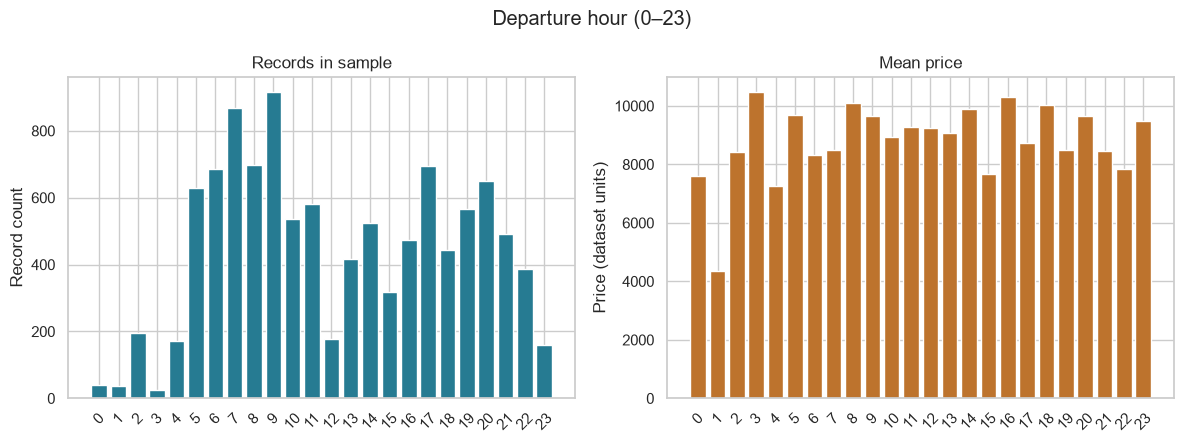

Highest mean: 03:00; lowest mean: 01:00.


In [8]:
hourly = summarize('Departure_Hour')
display(hourly.round(2))
plot_summary(hourly, 'Departure hour (0–23)', 'departure-prices.png')
print(f'Highest mean: {hourly["Mean"].idxmax():02d}:00; lowest mean: {hourly["Mean"].idxmin():02d}:00.')


## Reproducibility checks
These checks catch date ambiguity, non-stop/leg confusion, lost records during grouping, and non-finite aggregates. Missing stop counts are accounted for explicitly.


In [9]:
assert pd.to_datetime('01/05/2019', format='%d/%m/%Y') == pd.Timestamp(2019, 5, 1)
assert parse_stops(pd.Series(['non-stop', '1 stop', '2 stops', None])).iloc[:3].tolist() == [0, 1, 2]
assert pd.isna(parse_stops(pd.Series([None])).iloc[0])
try:
    parse_stops(pd.Series(['unknown']))
except ValueError:
    pass
else:
    raise AssertionError('Unexpected stop labels must fail validation')
assert int(pd.Series(['A→B']).str.count('→').iloc[0]) - 1 == 0
assert int(pd.Series(['A→B→C']).str.count('→').iloc[0]) - 1 == 1
for table in [airline_summary, monthly, weekday, hourly]:
    assert table['Count'].sum() == len(df)
    assert np.isfinite(table[['Mean', 'Median']].to_numpy()).all()
assert stops['Count'].sum() + df['Stops'].isna().sum() == len(df)
assert np.isfinite(stops[['Mean', 'Median']].to_numpy()).all()
assert df['Month_Number'].between(1, 12).all()
assert raw.equals(pd.read_excel(data_path)), 'Input data must remain unchanged'
print('All analysis checks passed.')


All analysis checks passed.


## Conclusions and scope
The tables and charts above describe the supplied sample. Month, weekday, airline, departure-hour, and stop groups have different sample sizes and may differ in other characteristics. They should not be interpreted as causal effects, passenger demand, or current travel advice.

There is no predictive model or live airline connection. Before extending this work, establish the dataset source, currency, sampling process, and duplication policy. Re-run every cell after changing input data; review quality counts and rare groups before drawing conclusions.
